# Setup

In [1]:
from pathlib import Path
import re
import sys
 
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pytesseract

In [2]:
data_dir = Path.cwd().resolve().parents[2] / "data" / "scale_ocr"  # modules/scale_ocr/scratch -> repo root
bmode_img_path = data_dir / "input" / "full_b_mode.png"
doppler_img_path = data_dir / "input" / "half_b_half_doppler.png"

# Define Regions of Interest

In [22]:
# ---------------------------------------------------------------------------
# Regions of interest, defined on a 1024x768 reference frame (x0, y0, x1, y1).
# They are rescaled automatically if your frames are a different size.
# ---------------------------------------------------------------------------
REF_W, REF_H = 1024, 768
ROIS = {
    "header":        (0,   0,   1024, 45),
    "params":        (745, 40,  900,  350),   # MI, Depth, SV size, Angle, ...
    "depth_scale":   (705, 40,  760,  350),   # cyan 0-4 numbers (B-mode depth, cm)
    "depth_scale_b_only":   (705, 40,  760,  640),   # full screen bmode scale
    "velocity_axis": (28,  350, 76,   640),   # -180 ... 60 (cm/s)
    "footer":        (600, 650, 900,  680),
}
 
UPSCALE = 3  # Tesseract does much better on larger text

In [4]:
# image helper functions
def scaled_roi(img, name):
    h, w = img.shape[:2]
    x0, y0, x1, y1 = ROIS[name]
    sx, sy = w / REF_W, h / REF_H
    return int(x0 * sx), int(y0 * sy), int(x1 * sx), int(y1 * sy)
 
 
def crop(img, name):
    x0, y0, x1, y1 = scaled_roi(img, name)
    return img[y0:y1, x0:x1], (x0, y0)

In [5]:
# Preprocessing helpers
def prep_light_on_dark(roi_bgr):
    """White/grey text on black -> black text on white, upscaled and binarised."""
    gray = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=UPSCALE, fy=UPSCALE, interpolation=cv2.INTER_CUBIC)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.bitwise_not(th)
    return cv2.copyMakeBorder(th, 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=255)
 
 
def prep_cyan(roi_bgr):
    """Isolate the cyan scale numbers by colour, ignoring the grey image."""
    hsv = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, (80, 80, 80), (105, 255, 255))  # cyan-ish hues
    mask = cv2.resize(mask, None, fx=UPSCALE, fy=UPSCALE, interpolation=cv2.INTER_CUBIC)
    mask = cv2.bitwise_not(mask)  # black text on white
    return cv2.copyMakeBorder(mask, 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=255)

In [6]:
# ocr helpers
def ocr_words(prepped, offset, psm=11, whitelist=None):
    """Return [{text, conf, cx, cy, box}] with coords in ORIGINAL image pixels."""
    cfg = f"--oem 3 --psm {psm}"
    if whitelist:
        cfg += f" -c tessedit_char_whitelist={whitelist}"
    data = pytesseract.image_to_data(prepped, config=cfg, output_type=pytesseract.Output.DICT)
 
    pad = 10
    ox, oy = offset
    words = []
    for i, txt in enumerate(data["text"]):
        txt = txt.strip()
        if not txt or float(data["conf"][i]) < 0:
            continue
        x, y = data["left"][i] - pad, data["top"][i] - pad
        w, h = data["width"][i], data["height"][i]
        x0, y0 = ox + x / UPSCALE, oy + y / UPSCALE
        x1, y1 = x0 + w / UPSCALE, y0 + h / UPSCALE
        words.append({
            "text": txt,
            "conf": float(data["conf"][i]),
            "cx": (x0 + x1) / 2,
            "cy": (y0 + y1) / 2,
            "box": (int(x0), int(y0), int(x1), int(y1)),
        })
    return words
 
 
def fit_axis(words, label):
    """Linear fit value = a * pixel_y + b from numeric tick labels."""
    pts = []
    for w in words:
        m = re.fullmatch(r"-?\d+", w["text"])
        if m:
            pts.append((w["cy"], int(w["text"])))
    if len(pts) < 2:
        print(f"[{label}] not enough numeric labels found: {pts}")
        return None
    ys, vals = zip(*pts)
    a, b = np.polyfit(ys, vals, 1)
    resid = np.abs(np.array(vals) - (a * np.array(ys) + b)).max()
    print(f"[{label}] labels (y_px, value): {sorted(pts)}")
    print(f"[{label}] value = {a:.4f} * y + {b:.2f}   (max residual {resid:.2f})")
    print(f"[{label}] -> {abs(1 / a):.3f} px per unit")
    return a, b
 
 

In [ ]:
# parsers for each region
def read_params(img):
    roi, off = crop(img, "params")
    text = pytesseract.image_to_string(prep_light_on_dark(roi), config="--oem 3 --psm 6")
    print("\n--- raw parameter text ---")
    print(text)
 
    patterns = {
        "depth_cm":   r"Depth\s*([\d.]+)\s*cm",
        "frame_rate": r"([\d.]+)\s*Hz",
        "heart_rate": r"([\d.]+)\s*bpm",
        "sv_size_mm": r"SV\s*size\s*([\d.]+)\s*mm",
        "sv_depth_cm": r"SV\s*dep\s*([\d.]+)\s*cm",
        "freq_mhz":   r"Freq\s*([\d.]+)\s*MHz",
        "prf_khz":    r"PRF\s*([\d.]+)\s*kHz",
        "angle_deg":  r"Angle\s*(\d+)",
        "mi":         r"MI\s*([\d.]+)",
    }
    out = {}
    for key, pat in patterns.items():
        m = re.search(pat, text, flags=re.I)
        if m:
            out[key] = float(m.group(1))
    return out
 
 
def read_depth_scale(img, bmode_only = False):
    roi, off = crop(img, "depth_scale" if not bmode_only else "depth_scale_bmode")
    words = ocr_words(prep_cyan(roi), off, psm=11, whitelist="0123456789")
    return words, fit_axis(words, "depth (cm)")
 
 
def read_velocity_axis(img):
    roi, off = crop(img, "velocity_axis")
    words = ocr_words(prep_light_on_dark(roi), off, psm=11, whitelist="-0123456789")
    return words, fit_axis(words, "velocity (cm/s)")
 
 
def read_header(img):
    roi, _ = crop(img, "header")
    text = pytesseract.image_to_string(prep_light_on_dark(roi), config="--oem 3 --psm 6")
    return text.strip()

# Load Images

In [8]:
bmode_img = cv2.imread(bmode_img_path)
if bmode_img is None:
    sys.exit(f"Could not read {bmode_img_path}")
print(f"Loaded {bmode_img_path}: {bmode_img.shape[1]}x{bmode_img.shape[0]}")

print("\nHeader:", read_header(bmode_img))

Loaded c:\Users\khagy\GitHub\Capstone-Throwaway-Tests\scale_ocr\assets\full_b_mode.png: 1024x768

Header: terason 5-OCT-2026 le _ mj —|
Arterial Upper Extremity 02:52:56 PM uSmart3300


In [15]:
doppler_img = cv2.imread(doppler_img_path)
if doppler_img is None:
    sys.exit(f"Could not read {doppler_img_path}")
print(f"Loaded {doppler_img_path}: {doppler_img.shape[1]}x{doppler_img.shape[0]}")

print("\nHeader:", read_header(doppler_img))

Loaded c:\Users\khagy\GitHub\Capstone-Throwaway-Tests\scale_ocr\assets\half_b_half_doppler.png: 1024x768

Header: 5-OCT-2026 =


# Test doppler and bmode first

In [16]:
params = read_params(doppler_img)
print("\nParsed parameters:", params)


--- raw parameter text ---
~~ MI 0.4 |
— TIS <0.4
— 15L4A
-E/3/M/T¥3
_Gn50 DR60
4
__ Depth 4 cm
30 Hz
_ 66bpm
_ Invert
__ SV size 4.5mm
_ S¥ dep 1.3cm
Freq 4.5MHz
~ PRF 8.00kHz
— WF OFF
— Angle 60°


Parsed parameters: {'depth_cm': 4.0, 'frame_rate': 30.0, 'heart_rate': 66.0, 'sv_size_mm': 4.5, 'freq_mhz': 4.5, 'prf_khz': 8.0, 'angle_deg': 60.0, 'mi': 0.4}


In [17]:
depth_words, depth_fit = read_depth_scale(doppler_img)
vel_words, vel_fit = read_velocity_axis(doppler_img)

[depth (cm)] labels (y_px, value): [(51.0, 0), (123.0, 1), (195.0, 2), (266.0, 3), (338.5, 4)]
[depth (cm)] value = 0.0139 * y + -0.71   (max residual 0.01)
[depth (cm)] -> 71.801 px per unit
[velocity (cm/s)] labels (y_px, value): [(372.0, -180), (403.0, -150), (434.0, -120), (465.0, -90), (496.0, -60), (527.0, -30), (589.0, 30), (620.0, 60)]
[velocity (cm/s)] value = 0.9677 * y + -540.00   (max residual 0.00)
[velocity (cm/s)] -> 1.033 px per unit


In [18]:
# Sanity check: depth scale from tick labels vs the "Depth 4 cm" readout
if depth_fit and "depth_cm" in params:
    a, b = depth_fit
    print(f"\nDepth check: 0 cm at y={-b / a:.1f}px, "
            f"{params['depth_cm']:.0f} cm at y={(params['depth_cm'] - b) / a:.1f}px")


Depth check: 0 cm at y=51.1px, 4 cm at y=338.3px


In [19]:
# Debug image: draw ROIs and OCR'd boxes
dbg = doppler_img.copy()
for name in ROIS:
    x0, y0, x1, y1 = scaled_roi(doppler_img, name)
    cv2.rectangle(dbg, (x0, y0), (x1, y1), (0, 255, 255), 1)
    cv2.putText(dbg, name, (x0, max(y0 - 3, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)
for w in depth_words + vel_words:
    x0, y0, x1, y1 = w["box"]
    cv2.rectangle(dbg, (x0, y0), (x1, y1), (0, 0, 255), 1)
    cv2.putText(dbg, w["text"], (x1 + 2, y1), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)

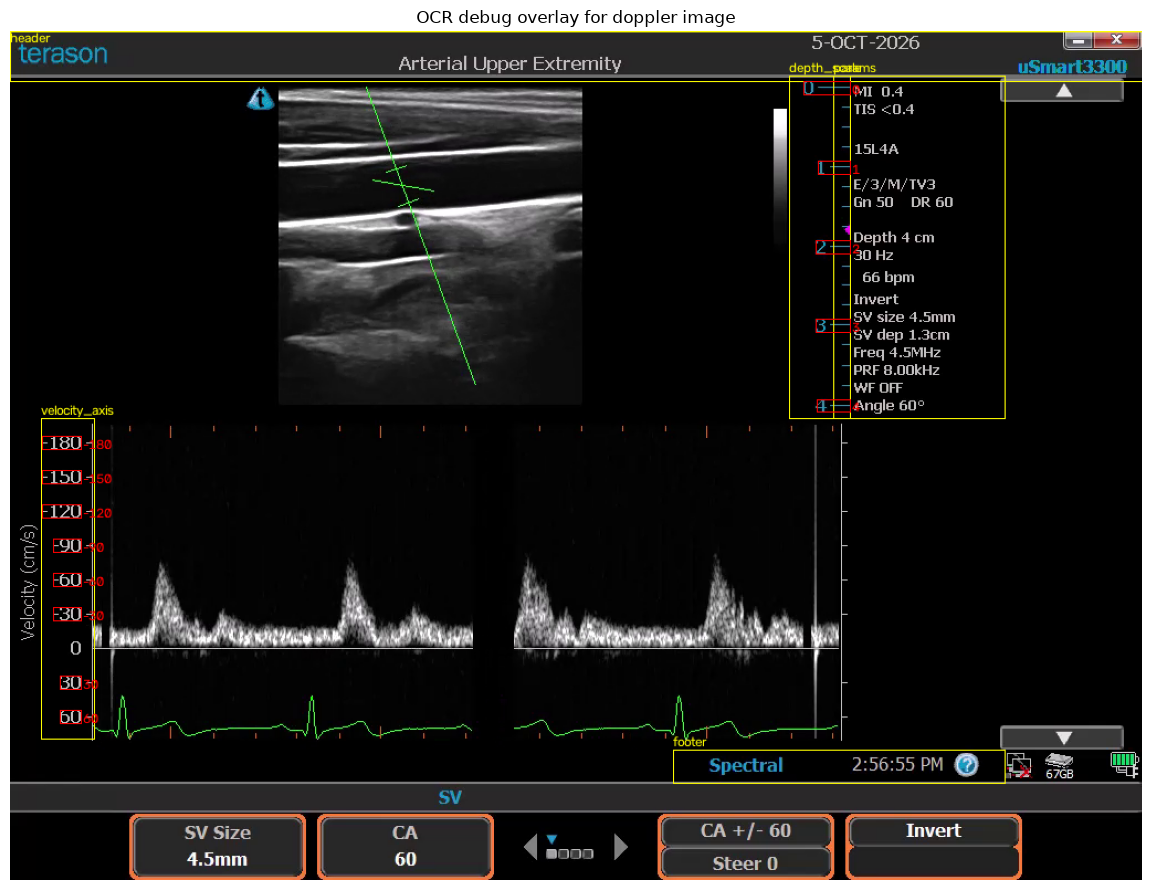

In [20]:
# Show the overlay inline (works in Jupyter and in a normal script window)
plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(dbg, cv2.COLOR_BGR2RGB))  # OpenCV is BGR, matplotlib wants RGB
plt.axis("off")
plt.title("OCR debug overlay for doppler image")
plt.tight_layout()
plt.show()

# Test b-mode only

In [21]:
params = read_params(bmode_img)
print("\nParsed parameters:", params)


--- raw parameter text ---
~~ MI 1.4 |
_ TIS <0.4
- 15L4A
— OM/E/3/M/TV¥3
\ Gn50 DR 60
~ THI
__ Depth 4cm
33 Hz
- (--- BPM)
4


Parsed parameters: {'depth_cm': 4.0, 'frame_rate': 33.0, 'mi': 1.4}


# END